In [1]:
import numpy as np
from optiland import optic

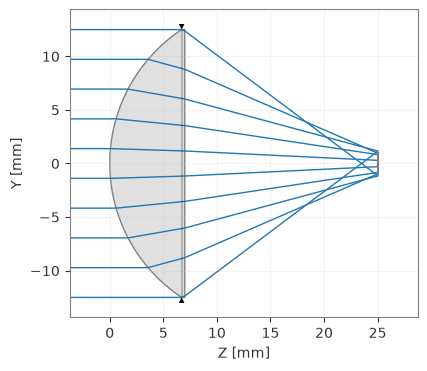

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [2]:
singlet = optic.Optic()

# define surfaces
singlet.surfaces.add(index=0, radius=np.inf, thickness=np.inf)
singlet.surfaces.add(index=1, radius=15, thickness=7, is_stop=True, material="N-BK7")
singlet.surfaces.add(index=2, radius=np.inf, thickness=18)
singlet.surfaces.add(index=3)

# define aperture
singlet.set_aperture(aperture_type="EPD", value=25)

# define fields
singlet.fields.set_type(field_type="angle")
singlet.fields.add(y=0)

# define wavelengths
singlet.wavelengths.add(value=0.5, is_primary=True)

# draw it
singlet.draw(num_rays=10)

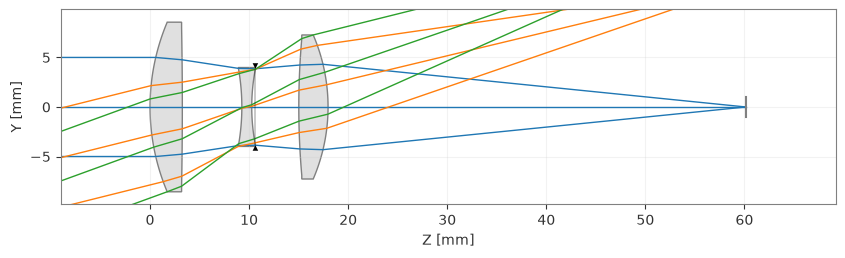

(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

In [3]:
from optiland.samples.objectives import CookeTriplet
from optiland.prescription import Prescription

lens = CookeTriplet()
lens.draw()
#p = Prescription(lens)
#p.view()

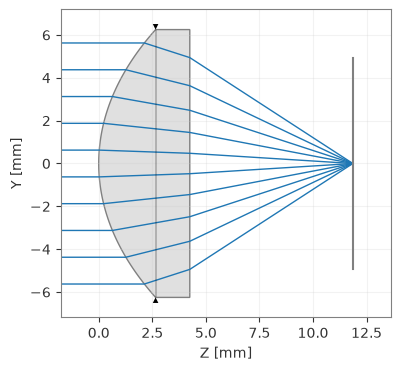

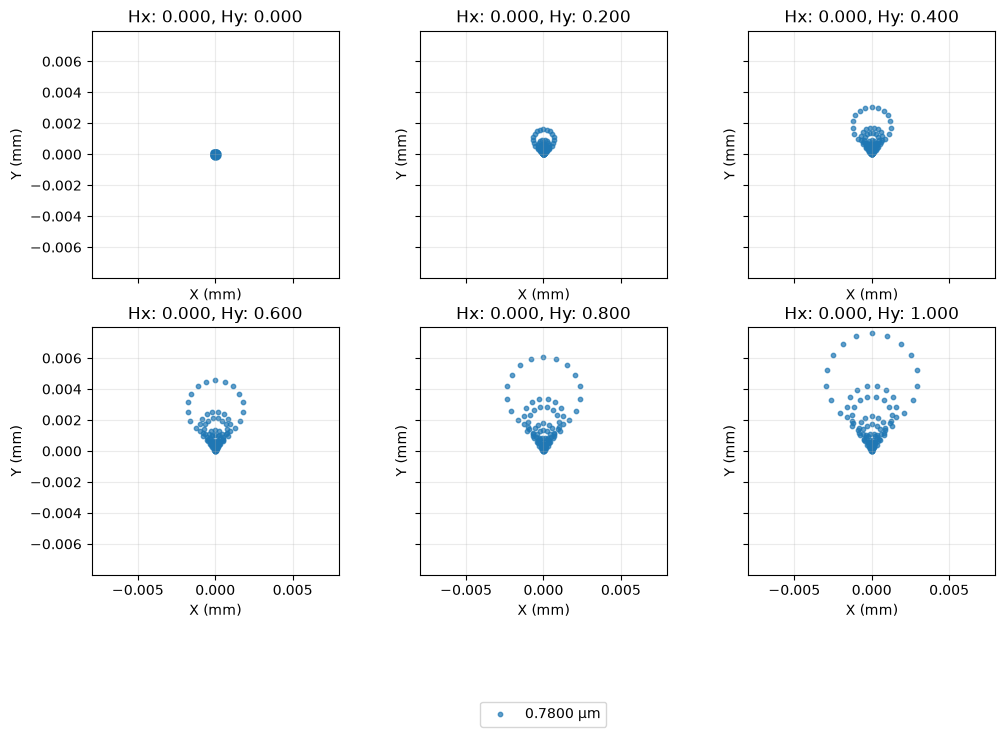

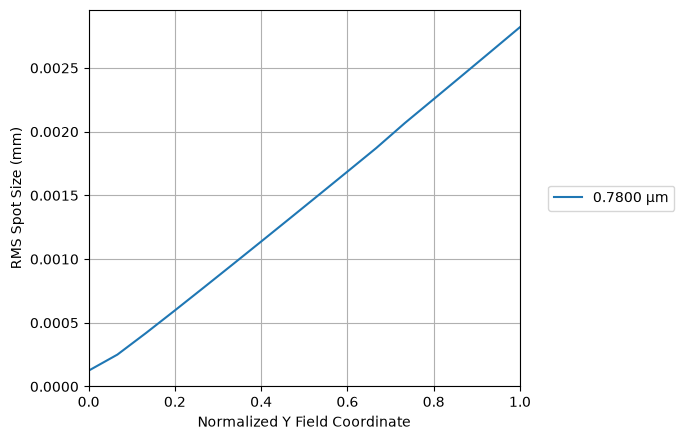

Optimized RMS spot radius by field (um):
[[np.float64(0.00012427942811833457)], [np.float64(0.0005970732482212081)], [np.float64(0.001137590518814126)], [np.float64(0.0016865277004169735)], [np.float64(0.0022550686253434856)], [np.float64(0.0028201531886217902)]]


In [29]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram

new_system = load_zemax_file("C:/Users/saten/Downloads/AL1210-Zemax-ZMX.zmx")
new_system.draw(num_rays=10)

filed_separation = 1/17
num_fields = 5
for i in range(num_fields):
    new_system.fields.add(y=(i+1)*filed_separation)

#p = Prescription(new_system)
#p.view()

spot = SpotDiagram(new_system, num_rings = 6, fields = "all")
spot.view()
#RayFan(new_system).view()
RmsSpotSizeVsField(new_system, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())

In [32]:
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram
from optiland.diagnostics import check_system
from optiland.optic import Optic
from optiland.solves import QuickFocusSolve

new_system.set_aperture(aperture_type="EPD", value=8)
new_system.wavelengths.remove(index = 0)
new_system.wavelengths.add(value = 1.55)
#filed_separation = 1/17
#num_fields = 5
#for i in range(num_fields):
#    new_system.fields.add(y=(i+1)*filed_separation)
focusing = QuickFocusSolve(new_system)
focusing.apply()

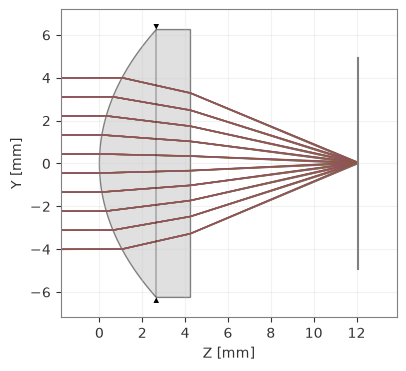

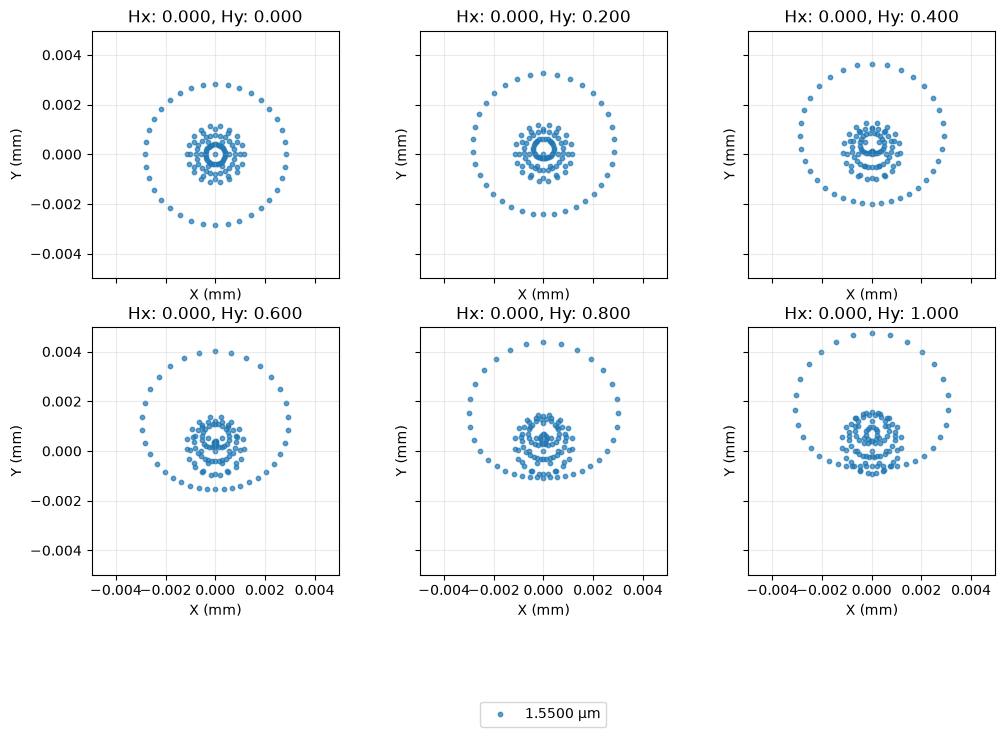

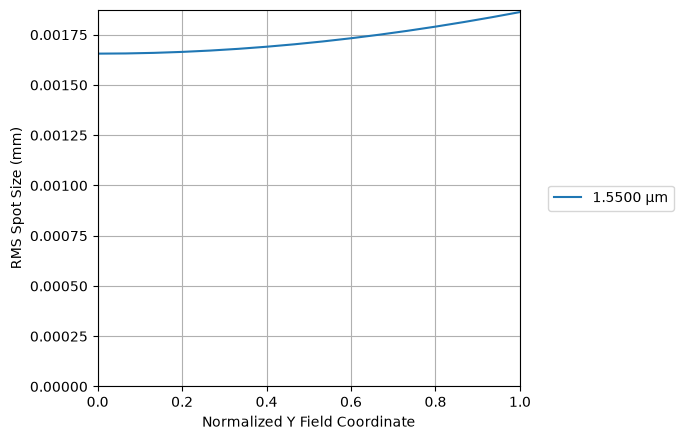

Optimized RMS spot radius by field (um):
[[np.float64(0.0016559012557959072)], [np.float64(0.0016645355147066744)], [np.float64(0.0016902369843653628)], [np.float64(0.0017324314958019047)], [np.float64(0.0017902520156438033)], [np.float64(0.001862645912431267)]]


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Optical Prescription — Aspheric Lens, Ø12.5mm, EFL = 10.0mm, NA=0.545                                           │
╰──────────────────────────────────────── Generated: 2026-11-09 12:01 UTC ────────────────────────────────────────╯

───────────────────────────────────────────────── System Overview ─────────────────────────────────────────────────

 Name              Aspheric Lens, Ø12.5mm, EFL = 10.0mm, NA=0.545  
  Surfaces          2                                               
  Stop Surface      1.0000                                          
  Aperture Type     EPDAperture                                     
  Aperture Value    8.0000                                          
  Object Distance   ∞                                               
  Image Distance    7.6098                                         

 Wavelengths

 #   Wavelength (µm)   Primary  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1   1.5500            ✓

... (6 outputs left out)

──────────────────────────────────────────── Surface Data — Materials ─────────────────────────────────────────────

 S#   Material   nd       Vd        Semi-Diameter (mm)   Coating  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  0    Air        1.0000   —         —                    —        
  1    S-LAH64    1.7880   47.3685   —                    —        
  2    Air        1.0000   —         —                    —        
  3    Air        1.0000   —         —                    —       

───────────────────────────────────────── Seidel Aberration Coefficients ──────────────────────────────────────────

 S#      SI (Sph)    SII (Coma)   SIII (Astig)   SIV (Petz)   SV (Dist)   CL (LCA)   CT (TCA)  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  1       0.280808    -0.001335    -0.000013      -0.000023    -0.000000   N/A        N/A       
  2       -0.123856   0.001625     -0.000021      0.000000     0.000000    N/A        N/A       
  Total   0.156952    0.000290     -0.000035      -0.000023    -0.000000   N/A        N/A

In [33]:
new_system.draw(num_rays=10)
spot = SpotDiagram(new_system, num_rings = 6, fields = "all")
spot.view()
#RayFan(new_system).view()
RmsSpotSizeVsField(new_system, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())

p = Prescription(new_system)
p.view()

In [ ]:
from optiland.fileio import load_optiland_file, save_optiland_file
from optiland.fileio import load_zemax_file
from optiland.analysis import RayFan, RmsSpotSizeVsField, SpotDiagram

new_system1 = load_zemax_file("C:/Users/saten/Downloads/ASL1210-Zemax-ZMX.zmx")
new_system1.draw(num_rays=10)

filed_separation = 1/17
num_fields = 5
for i in range(num_fields):
    new_system.fields.add(y=(i+1)*filed_separation)

#p = Prescription(new_system)
#p.view()

spot = SpotDiagram(new_system, num_rings = 6, fields = "all")
spot.view()
#RayFan(new_system).view()
RmsSpotSizeVsField(new_system, num_fields = 16).view()

print("Optimized RMS spot radius by field (um):")
print(spot.rms_spot_radius())

c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\materials\abbe.py:183: RuntimeWarning: divide by zero encountered in divide
  inv_v = 1.0 / vd
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\materials\abbe.py:184: RuntimeWarning: divide by zero encountered in divide
  inv_v2 = 1.0 / (vd**2)
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\materials\abbe.py:186: RuntimeWarning: invalid value encountered in divide
  nd_div_v = nd / vd
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\materials\abbe.py:203: RuntimeWarning: invalid value encountered in add
  v2 = c[0] + c[1] * inv_v + c[2] * inv_v2 + c[3] * nd_sq + c[4] * nd_div_v
c:\Users\saten\Documents\Umberto\Repositories\OpticalEngineering\.venv\Lib\site-packages\optiland\materials\abbe.py:208: RuntimeWarning: invalid value encountered in ad

ValueError: Unsupported Zemax surface type: qed_type